# K - Nearest Neighbour Algorithm -- Regression

# 1 - Import Libraries

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 2 - Load Data Set

In [2]:
housing = fetch_california_housing()

X = housing.data
y = housing.target

In [4]:
df = pd.DataFrame(X, columns=housing.feature_names)

df['Price'] = y

print("Five rows of the dataset:\n")
print(df.head())

Five rows of the dataset:

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  Price  
0    -122.23  4.526  
1    -122.22  3.585  
2    -122.24  3.521  
3    -122.25  3.413  
4    -122.25  3.422  


# 3 - Data Visualization

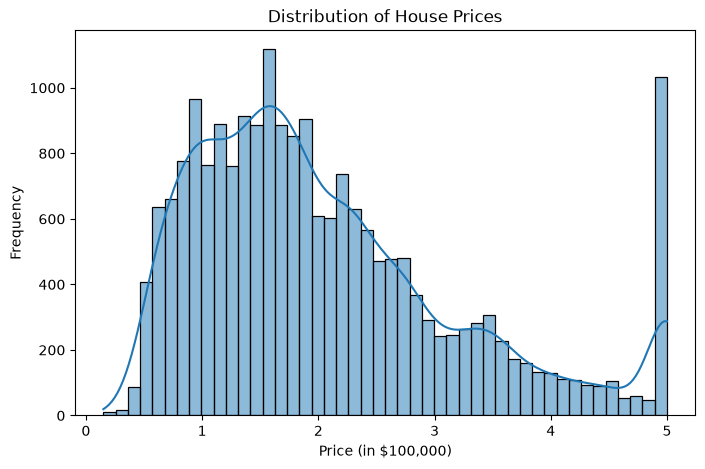

In [7]:
plt.figure(figsize=(8, 5))

sns.histplot(df['Price'], kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("Price (in $100,000)")
plt.ylabel("Frequency")

plt.show()

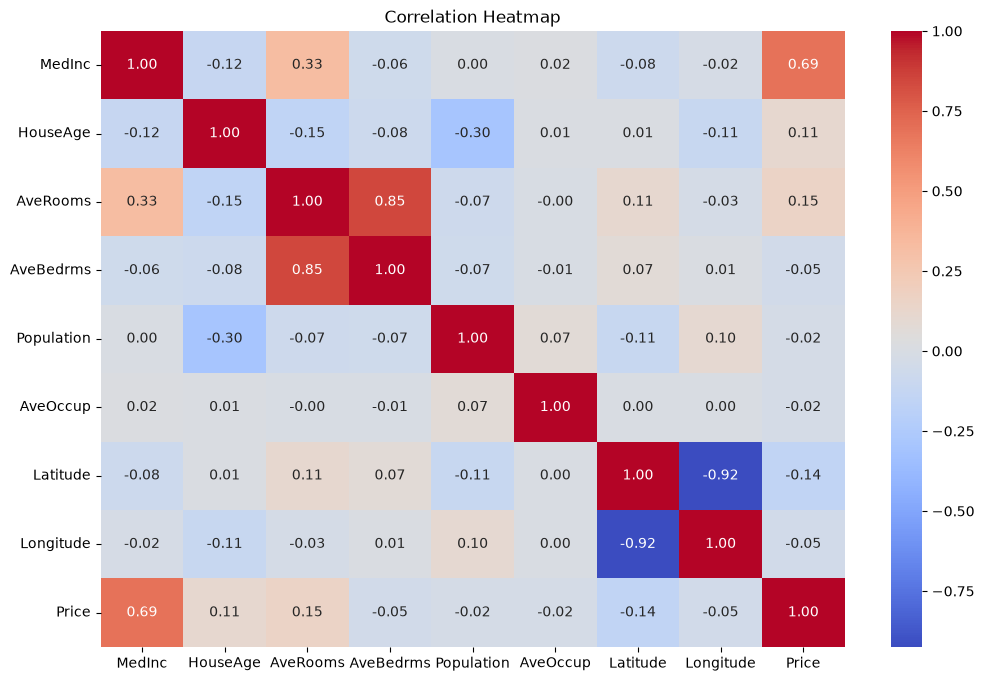

In [5]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

# 4 - Training and Testing Data Split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (16512, 8)
Testing Data: (4128, 8)


## 4.1 Feature Scaling

In [8]:
scalar = StandardScaler()

X_train = scalar.fit_transform(X_train)

X_test = scalar.transform(X_test)

# 5 - Model Training

In [9]:
knn = KNeighborsRegressor(n_neighbors=5)

knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


# 6 - Predictions

In [10]:
y_prediction = knn.predict(X_test)

In [11]:
print("Actual Values:")
print(y_test[:10])

Actual Values:
[0.477   0.458   5.00001 2.186   2.78    1.587   1.982   1.575   3.4
 4.466  ]


In [12]:
comparison = pd.DataFrame({
    'Actual Price': y_test[:10],
    'Predicted Price': y_prediction[:10]
})

print(comparison)

   Actual Price  Predicted Price
0       0.47700         0.498800
1       0.45800         0.764600
2       5.00001         4.750006
3       2.18600         2.876600
4       2.78000         2.726200
5       1.58700         1.778600
6       1.98200         2.718200
7       1.57500         1.924600
8       3.40000         2.031400
9       4.46600         4.955608


# 7 - Model Evaluation

In [15]:
import numpy  as np
mae = mean_absolute_error(y_test, y_prediction)

mse = mean_squared_error(y_test, y_prediction)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_prediction)

print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")

Mean Absolute Error (MAE): 0.4462
Mean Squared Error (MSE): 0.4324
Root Mean Squared Error (RMSE): 0.6576
R2 Score: 0.6700


# 8 - Actual vs Predicted Values

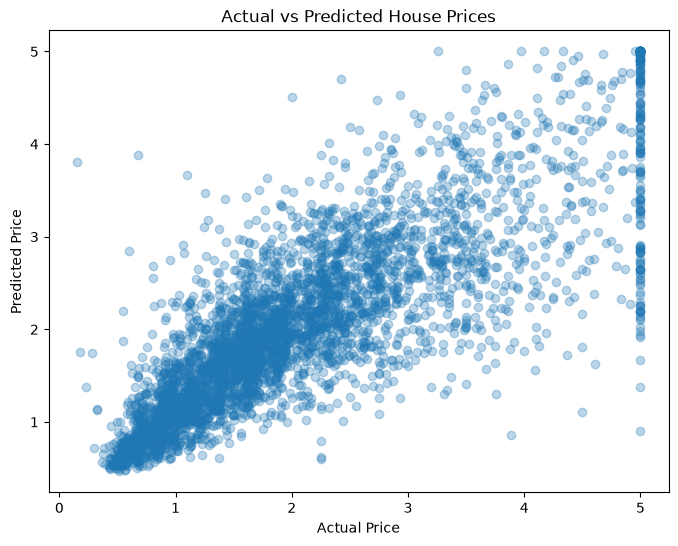

In [16]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_prediction, alpha=0.3)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

plt.title("Actual vs Predicted House Prices")

plt.show()

# 9 - Residual Plot

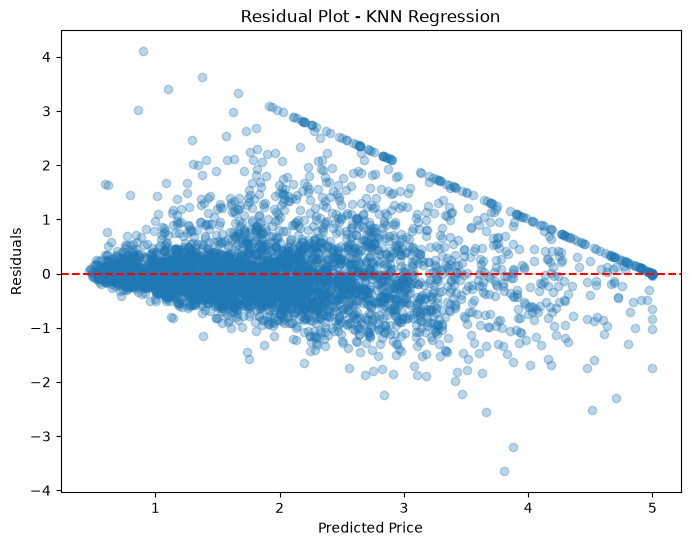

In [17]:
residuals = y_test - y_prediction

plt.figure(figsize=(8, 6))

plt.scatter(y_prediction, residuals, alpha=0.3)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Price")
plt.ylabel("Residuals")

plt.title("Residual Plot - KNN Regression")

plt.show()

# 10 - Custom Prediction

In [19]:
sample_data = pd.DataFrame(
    [[3.5, 20, 5.0, 1.0, 1000, 3.0, 34.0, -118.0]],
    columns=housing.feature_names
)

sample_scaled = scalar.transform(sample_data.to_numpy())

prediction = knn.predict(sample_scaled)

print(f"Predicted House Price: ${prediction[0] * 100000:,.2f}")

Predicted House Price: $193,840.00
